<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Scatter Plot**


Estimated time needed: **45** minutes


## Overview

In this lab, you will focus on creating and interpreting scatter plots to visualize relationships between variables and trends in the dataset. The provided dataset will be directly loaded into a pandas DataFrame, and various scatter plot-related visualizations will be created to explore developer trends, compensation, and preferences.



## Objectives


In this lab, you will:

- Create and analyze scatter plots to examine relationships between variables.

- Use scatter plots to identify trends and patterns in the dataset.

- Focus on visualizations centered on scatter plots for better data-driven insights.


## Setup: Working with the Database



**Install and import the required libraries**


In [6]:
!pip install pandas
!pip install matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#### Step 1: Load the dataset


In [7]:
file_path = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv"

df = pd.read_csv(file_path)
survey_df=df.copy()
print(f'Righe {len(survey_df):,} colonne: {survey_df.shape[1]}')

Righe 65,437 colonne: 114



### Task 1: Exploring Relationships with Scatter Plots



#### 1. Scatter Plot for Age vs. Job Satisfaction



Visualize the relationship between respondents' age (`Age`) and job satisfaction (`JobSatPoints_6`). Use this plot to identify any patterns or trends.




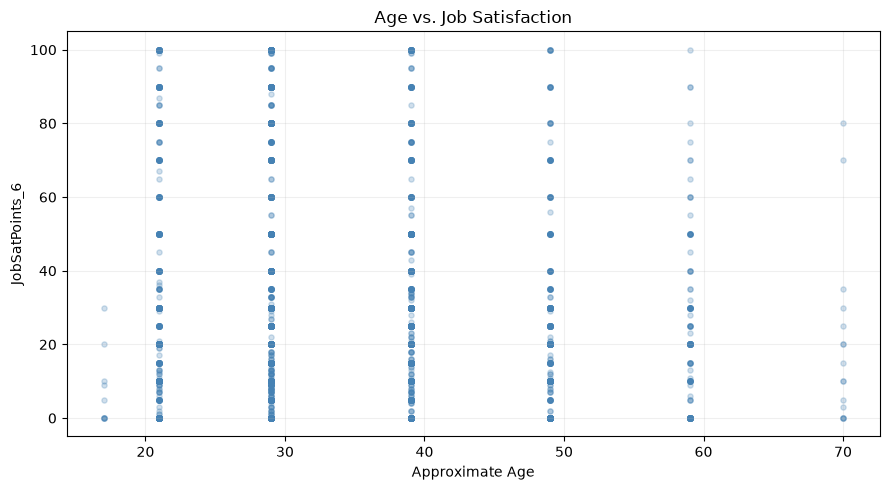

In [8]:
## Write your code here
age_map = {'Under 18 years old': 17, '18-24 years old': 21, '25-34 years old': 29, '35-44 years old': 39, '45-54 years old': 49, '55-64 years old': 59, '65 years or older': 70}
age_sat=survey_df[['Age','JobSatPoints_6']].copy()
age_sat['Age_numeric']=age_sat['Age'].map(age_map)
age_sat['JobSatPoints_6']=pd.to_numeric(age_sat['JobSatPoints_6'], errors='coerce')
age_sat=age_sat.dropna(subset=['Age_numeric', 'JobSatPoints_6'])
plot_data=age_sat.sample(min(5000,len(age_sat)),random_state=42)

plt.figure(figsize=(9,5))
plt.scatter(plot_data['Age_numeric'],plot_data['JobSatPoints_6'],alpha=0.25, s=14, color='steelblue')
plt.title('Age vs. Job Satisfaction')
plt.xlabel('Approximate Age')
plt.ylabel('JobSatPoints_6')
plt.tight_layout()
plt.grid(alpha=0.2)
plt.show()

#### 2. Scatter Plot for Compensation vs. Job Satisfaction


Explore the relationship between yearly compensation (`ConvertedCompYearly`) and job satisfaction (`JobSatPoints_6`) using a scatter plot.


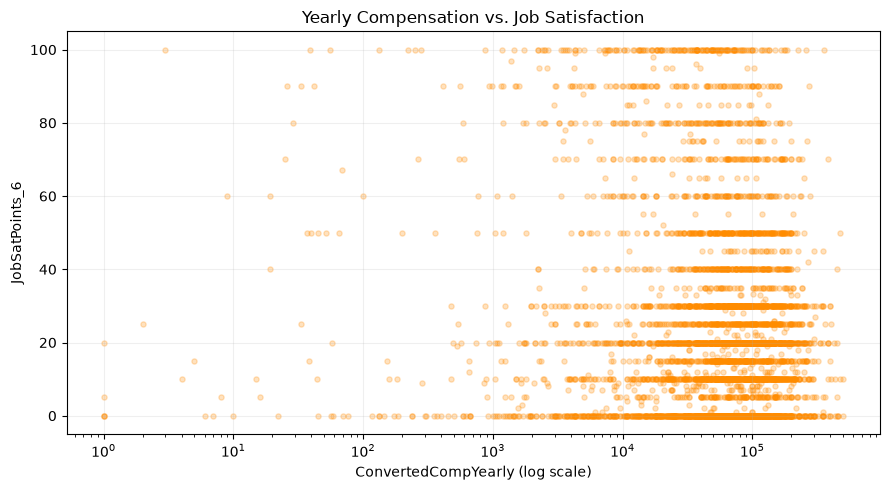

In [9]:
## Write your code here

comp_sat=survey_df[['ConvertedCompYearly','JobSatPoints_6']].copy()
comp_sat['ConvertedCompYearly']=pd.to_numeric(comp_sat['ConvertedCompYearly'], errors='coerce')
comp_sat['JobSatPoints_6']=pd.to_numeric(comp_sat['JobSatPoints_6'], errors='coerce')
comp_sat=comp_sat.dropna()
comp_sat=comp_sat[comp_sat['ConvertedCompYearly']>0]
comp_sat_cap=comp_sat['ConvertedCompYearly'].quantile(0.995)
comp_sat=comp_sat[comp_sat['ConvertedCompYearly']<=comp_sat_cap]

plot_data=comp_sat.sample(min(5000,len(comp_sat)),random_state=42)

plt.figure(figsize=(9,5))
plt.scatter(plot_data['ConvertedCompYearly'],plot_data['JobSatPoints_6'],alpha=0.25, s=14, color='darkorange')
plt.title('Yearly Compensation vs. Job Satisfaction')
plt.xscale('log')
plt.xlabel('ConvertedCompYearly (log scale)')
plt.ylabel('JobSatPoints_6')
plt.tight_layout()
plt.grid(alpha=0.2)
plt.show()

### Task 2: Enhancing Scatter Plots


#### 1. Scatter Plot with Trend Line for Age vs. Job Satisfaction



Add a regression line to the scatter plot of Age vs. JobSatPoints_6 to highlight trends in the data.


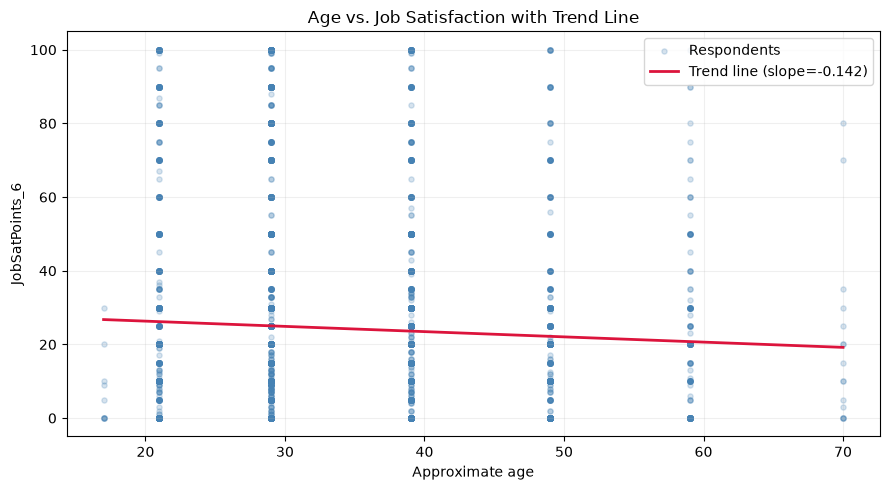

Correlation: -0.051


In [12]:
## Write your code here
trend=age_sat.copy()
x=trend['Age_numeric'].to_numpy()
y=trend['JobSatPoints_6'].to_numpy()
slope, intercept=np.polyfit(x,y,1)
x_line=np.linspace(x.min(),x.max(),100)

plt.figure(figsize=(9,5))
plot_data = trend.sample(min(5000, len(trend)), random_state=42)
plt.scatter(plot_data['Age_numeric'], plot_data['JobSatPoints_6'], alpha=0.22, s=14, color='steelblue', label='Respondents')
plt.plot(x_line, slope * x_line + intercept, color='crimson', linewidth=2, label=f'Trend line (slope={slope:.3f})')
plt.title('Age vs. Job Satisfaction with Trend Line')
plt.xlabel('Approximate age')
plt.ylabel('JobSatPoints_6')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print(f'Correlation: {trend["Age_numeric"].corr(trend["JobSatPoints_6"]):.3f}')

#### 2. Scatter Plot for Age vs. Work Experience


Visualize the relationship between Age (`Age`) and Work Experience (`YearsCodePro`) using a scatter plot.


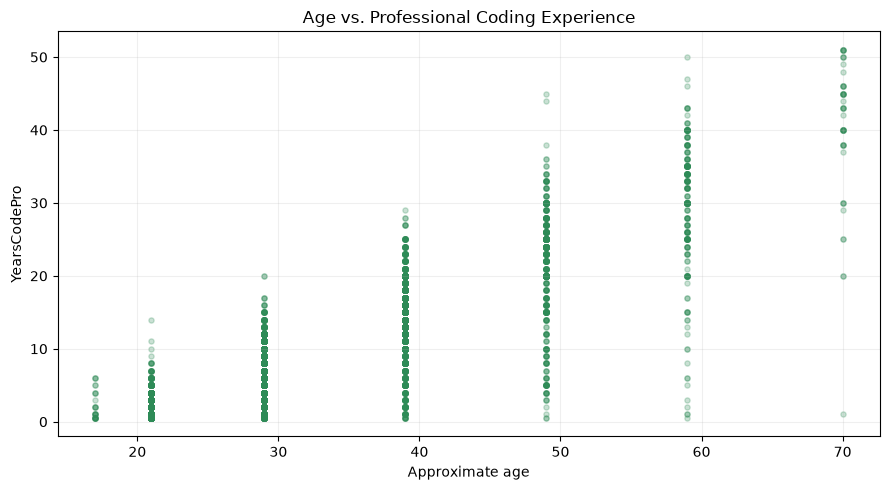

In [15]:
## Write your code here
experience = survey_df[['Age', 'YearsCodePro']].copy()
experience['Age_numeric'] = experience['Age'].map(age_map)
experience['YearsCodePro_numeric'] = experience['YearsCodePro'].replace({'Less than 1 year': '0.5', 'More than 50 years': '51'})
experience['YearsCodePro_numeric'] = pd.to_numeric(experience['YearsCodePro_numeric'], errors='coerce')
experience = experience.dropna(subset=['Age_numeric', 'YearsCodePro_numeric'])
experience = experience[(experience['YearsCodePro_numeric'] >= 0) & (experience['YearsCodePro_numeric'] <= 60)]
plot_data = experience.sample(min(5000, len(experience)), random_state=42)
plt.figure(figsize=(9, 5))
plt.scatter(plot_data['Age_numeric'], plot_data['YearsCodePro_numeric'], alpha=0.25, s=14, color='seagreen')
plt.title('Age vs. Professional Coding Experience')
plt.xlabel('Approximate age')
plt.ylabel('YearsCodePro')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Task 3: Combining Scatter Plots with Additional Features


#### 1. Bubble Plot of Compensation vs. Job Satisfaction with Age as Bubble Size



Create a bubble plot to explore the relationship between yearly compensation (`ConvertedCompYearly`) and job satisfaction (`JobSatPoints_6`), with bubble size representing age.


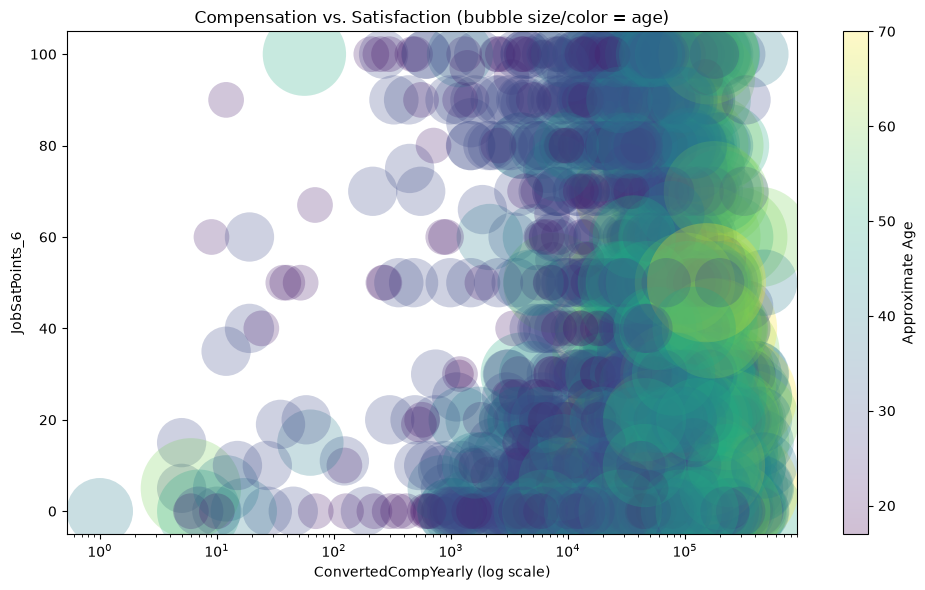

In [19]:
## Write your code here
bubble=survey_df[['ConvertedCompYearly','JobSatPoints_6','Age']].copy()
bubble['ConvertedCompYearly']=pd.to_numeric(bubble['ConvertedCompYearly'], errors='coerce')
bubble['JobSatPoints_6']=pd.to_numeric(bubble['JobSatPoints_6'], errors='coerce')
bubble['Age_numeric']=bubble['Age'].map(age_map)
bubble=bubble.dropna()
bubble = bubble[bubble['ConvertedCompYearly'] > 0]
bubble_cap = bubble['ConvertedCompYearly'].quantile(0.995)
bubble=bubble[bubble['ConvertedCompYearly']<bubble_cap]

plot_data=bubble.sample(min(4000,len(bubble)),random_state=42)
plt.figure(figsize=(10,6))
sizes=(plot_data['Age_numeric']**2)*1.5
plt.scatter(plot_data['ConvertedCompYearly'], plot_data['JobSatPoints_6'], s=sizes, alpha=0.25, c=plot_data['Age_numeric'] , cmap='viridis', edgecolors='none')
plt.xscale('log')
plt.colorbar(label='Approximate Age')
plt.title('Compensation vs. Satisfaction (bubble size/color = age)')
plt.xlabel('ConvertedCompYearly (log scale)')
plt.ylabel('JobSatPoints_6')
plt.tight_layout()
plt.show()

#### 2. Scatter Plot for Popular Programming Languages by Job Satisfaction


Visualize the popularity of programming languages (`LanguageHaveWorkedWith`) against job satisfaction using a scatter plot. Use points to represent satisfaction levels for each language.


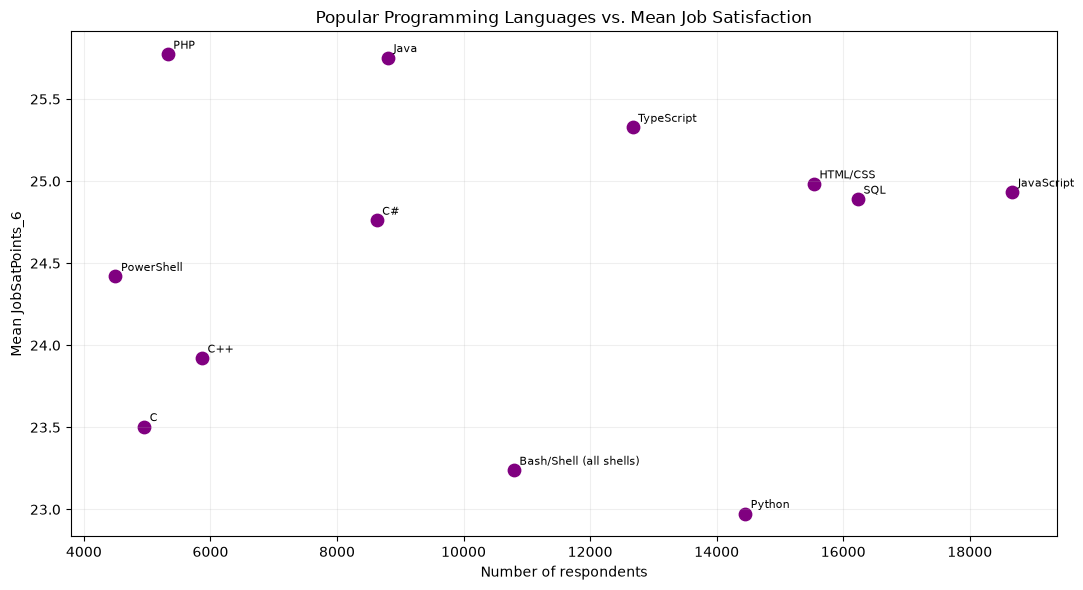

                   Language  Respondents  MeanSatisfaction
22               JavaScript        18673         24.932811
40                      SQL        16233         24.889480
19                 HTML/CSS        15537         24.983012
36                   Python        14450         22.974692
44               TypeScript        12671         25.327332
3   Bash/Shell (all shells)        10795         23.237911
21                     Java         8805         25.752243
5                        C#         8627         24.760905
6                       C++         5867         23.921340
32                      PHP         5325         25.772770
4                         C         4953         23.503650
34               PowerShell         4499         24.418926


In [21]:
## Write your code here
language_data= survey_df[['LanguageHaveWorkedWith','JobSatPoints_6']].copy()
language_data['JobSatPoints_6']=pd.to_numeric(language_data['JobSatPoints_6'], errors='coerce')
language_data=language_data.dropna(subset=['LanguageHaveWorkedWith','JobSatPoints_6'])
language_data['Language']=language_data['LanguageHaveWorkedWith'].astype(str).str.split(';')
language_data=language_data.explode('Language')
language_data['Language']=language_data['Language'].str.strip()
language_summary=language_data.groupby('Language').agg(Respondents=('Language', 'size'), MeanSatisfaction=('JobSatPoints_6', 'mean')).reset_index()
language_summary = language_summary.sort_values('Respondents', ascending=False).head(12)
plt.figure(figsize=(11, 6))
plt.scatter(language_summary['Respondents'], language_summary['MeanSatisfaction'], s=80, color='purple')
for _, row in language_summary.iterrows():
    plt.annotate(row['Language'], (row['Respondents'], row['MeanSatisfaction']), xytext=(4, 4), textcoords='offset points', fontsize=8)
plt.title('Popular Programming Languages vs. Mean Job Satisfaction')
plt.xlabel('Number of respondents')
plt.ylabel('Mean JobSatPoints_6')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print(language_summary)

### Task 4: Scatter Plot Comparisons Across Groups


#### 1. Scatter Plot for Compensation vs. Job Satisfaction by Employment Type


Visualize the relationship between yearly compensation (`ConvertedCompYearly`) and job satisfaction (`JobSatPoints_6`), categorized by employment type (`Employment`). Use color coding or markers to differentiate between employment types.


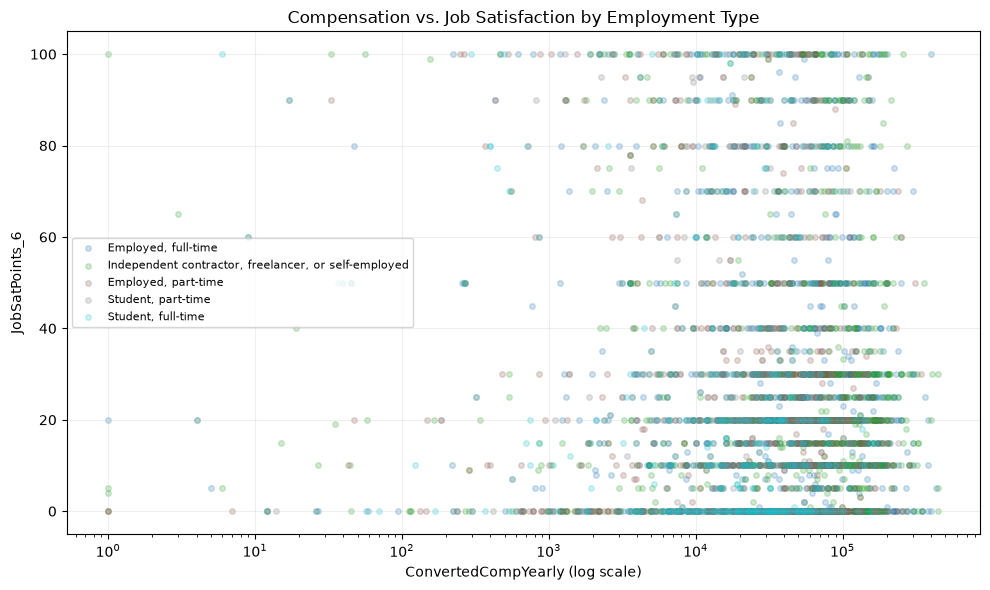

In [26]:
## Write your code here
employment=survey_df[['ConvertedCompYearly','JobSatPoints_6','Employment']].copy()
employment['JobSatPoints_6']=pd.to_numeric(employment['JobSatPoints_6'], errors='coerce')
employment['ConvertedCompYearly']=pd.to_numeric(employment['ConvertedCompYearly'], errors='coerce')
employment=employment.dropna()
employment = employment[employment['ConvertedCompYearly'] > 0]
employment_cap = employment['ConvertedCompYearly'].quantile(0.995)
employment=employment[employment['ConvertedCompYearly']<employment_cap]
employment['Employment']=employment['Employment'].astype(str).str.split(';')
employment=employment.explode('Employment')
employment['Employment']=employment['Employment'].str.strip()
top_employment=employment['Employment'].value_counts().head(5).index.to_list()
employment=employment[employment['Employment'].isin(top_employment)]

plt.figure(figsize=(10,6))
colors=plt.cm.tab10(np.linspace(0,1,len(top_employment)))
for color, group in zip(colors, top_employment):
    subset = employment[employment['Employment'] == group].sample(min(1200, (employment['Employment'] == group).sum()), random_state=42)
    plt.scatter(subset['ConvertedCompYearly'], subset['JobSatPoints_6'], s=16, alpha=0.22, color=color, label=group)
plt.xscale('log')
plt.title('Compensation vs. Job Satisfaction by Employment Type')
plt.xlabel('ConvertedCompYearly (log scale)')
plt.ylabel('JobSatPoints_6')
plt.legend(fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
                


#### 2. Scatter Plot for Work Experience vs. Age Group by Country


Compare work experience (`YearsCodePro`) across different age groups (`Age`) and countries (`Country`). Use colors to represent different countries and markers for age groups.


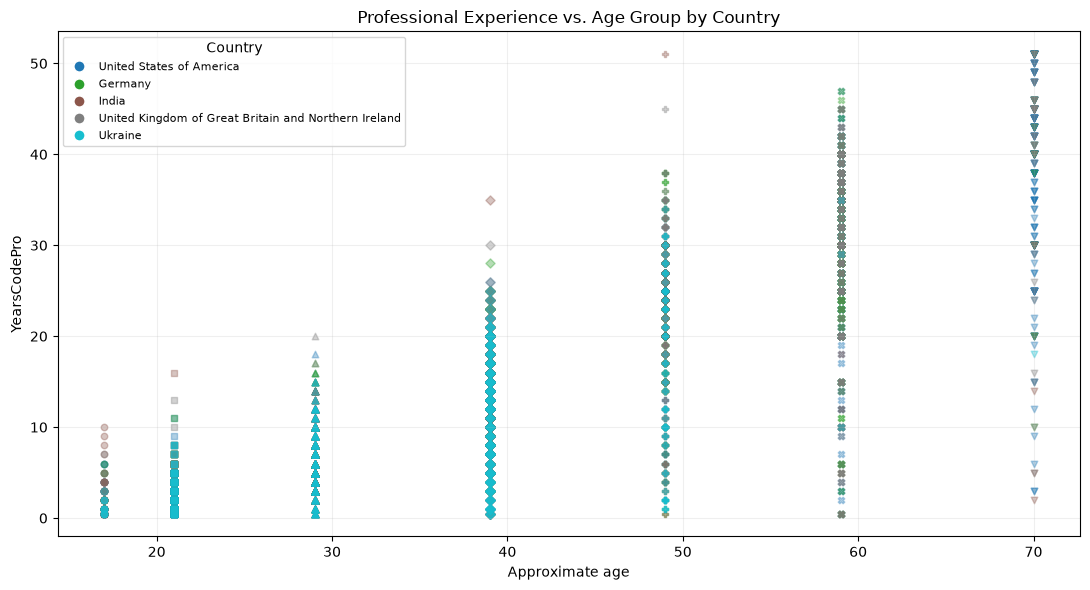

In [27]:
## Write your code here
country_age=survey_df[['YearsCodePro','Age','Country']]
country_age['YearsCodePro']=country_age['YearsCodePro'].replace({'Less than 1 year': '0.5', 'More than 50 years': '51'})
country_age['YearsCodePro']=pd.to_numeric(country_age['YearsCodePro'], errors='coerce')
country_age['Age_numeric']=country_age['Age'].map(age_map)
country_age=country_age.dropna(subset=['YearsCodePro','Age_numeric','Country'])
country_age = country_age[(country_age['YearsCodePro'] >= 0) & (country_age['YearsCodePro'] <= 60)]
top_countries = country_age['Country'].value_counts().head(5).index.tolist()
country_age = country_age[country_age['Country'].isin(top_countries)]
plt.figure(figsize=(11, 6))
markers = ['o', 's', '^', 'D', 'P', 'X', 'v']
age_order = list(age_map.keys())
for country, color in zip(top_countries, plt.cm.tab10(np.linspace(0, 1, len(top_countries)))):
    for marker, age_label in zip(markers, age_order):
        subset = country_age[(country_age['Country'] == country) & (country_age['Age'] == age_label)] 
        if len(subset) == 0: continue
        subset = subset.sample(min(250, len(subset)), random_state=42)
        plt.scatter(subset['Age_numeric'], subset['YearsCodePro'], s=22, alpha=0.35, color=color, marker=marker, label=f'{country} – {age_label}')
plt.title('Professional Experience vs. Age Group by Country')
plt.xlabel('Approximate age')
plt.ylabel('YearsCodePro')
# Show a compact country legend rather than one entry per marker/age combination.
handles, labels = plt.gca().get_legend_handles_labels()
country_handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=color, markersize=8, label=country) for country, color in zip(top_countries, plt.cm.tab10(np.linspace(0, 1, len(top_countries))))]
plt.legend(handles=country_handles, title='Country', fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Final Step: Review


With these scatter plots, you will have analyzed data relationships across multiple dimensions, including compensation, job satisfaction, employment types, and demographics, to uncover meaningful trends in the developer community.


### Summary


After completing this lab, you will be able to:
- Analyze how numerical variables relate across specific groups, such as employment types and countries.
- Use scatter plots effectively to represent multiple variables with color, size, and markers.
- Gain insights into compensation, satisfaction, and demographic trends using advanced scatter plot techniques.


## Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


<!--## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|               
|2024-10-07|1.2|Madhusudan Moole|Reviewed and updated lab|                                                                                      
|2024-10-06|1.0|Raghul Ramesh|Created lab|-->


Copyright © IBM Corporation. All rights reserved.
